# LAB 07 — Transformer Architecture (From Attention to Transformer)
**Môn học:** Xử lý ngôn ngữ tự nhiên và ứng dụng
**Học kỳ:** Học kỳ I - 2026 | **Giảng viên / TA:** Phạm Ngọc Hải

Notebook này triển khai đầy đủ các nội dung và thực nghiệm của **LAB 07**:
1. Triển khai Sinusoidal Positional Encoding & Thực nghiệm hoán vị (Permutation Experiment).
2. Xây dựng khối `TransformerBlock` tối giản từ các primitive layers (Multi-Head Attention, Residual, LayerNorm, FFN).
3. Khảo sát số lượng Attention Heads ($h \in \{1, 2, 4, 8\}$) với $d_{model}=128$.
4. Phân tích sự đa dạng của các Attention Heads (Heatmap visualization).
5. So sánh toàn diện giữa Transformer Encoder và LSTM baseline (kế thừa từ LAB 05).
6. Khảo sát ảnh hưởng của chiều dài chuỗi ($T \in \{32, 64, 128, 256\}$) và chi phí $O(T^2)$.
7. So sánh các chiến lược Pooling (Mean pooling vs CLS-style pooling).
8. Ứng dụng phân loại cảm xúc trên tập IMDb và đánh giá định tính các trường hợp đặc biệt.

## 1. Thiết lập môi trường và cấu hình hạt giống (Seed)
Đảm bảo tính tái lập (reproducibility) bằng cách cố định SEED cho Torch và NumPy.

In [1]:
import sys
import os
import re
import time
import math
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

# Seed & Device
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
torch.set_num_threads(4)

device = torch.device('cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu'))
print(f'Môi trường thực thi: {device}')

Môi trường thực thi: cpu


## 2. Tiền xử lý dữ liệu IMDb Dataset
Sử dụng cùng cấu trúc tập dữ liệu và tỷ lệ phân chia Train / Val / Test (80% / 10% / 10%) như ở **LAB 05** và **LAB 06** để kiểm soát biến thay đổi và đảm bảo so sánh công bằng.

In [2]:
# Tìm đường dẫn dataset IMDb
candidates = [
    Path('IMDB Dataset.csv'),
    Path('../IMDB Dataset.csv'),
    Path('/Users/user/NLP/IMDB Dataset.csv')
]
dataset_path = next((p for p in candidates if p.is_file()), None)
if dataset_path is None:
    raise FileNotFoundError('Không tìm thấy file IMDB Dataset.csv!')

df = pd.read_csv(dataset_path)
print(f'Đã đọc dataset từ: {dataset_path} | Số lượng mẫu: {len(df)}')

def tokenize(text):
    return re.findall(r"[a-z]+(?:'[a-z]+)?", text.lower())

# Phân chia Train / Val / Test cố định SEED=42
train_df, other = train_test_split(df, test_size=0.2, stratify=df.sentiment, random_state=SEED)
val_df, test_df = train_test_split(other, test_size=0.5, stratify=other.sentiment, random_state=SEED)
print(f'Phân chia: Train = {len(train_df)}, Val = {len(val_df)}, Test = {len(test_df)}')

# Xây dựng Vocabulary (10,000 từ phổ biến nhất)
VOCAB_SIZE = 10000
train_tokens = [tokenize(text) for text in train_df.review.fillna('')]
val_tokens = [tokenize(text) for text in val_df.review.fillna('')]
test_tokens = [tokenize(text) for text in test_df.review.fillna('')]

word_counts = Counter(w for words in train_tokens for w in words)
vocab = {w: i + 2 for i, (w, _) in enumerate(word_counts.most_common(VOCAB_SIZE - 2))}
# ID 0: <PAD>, ID 1: <UNK>
print(f'Kích thước từ vựng xây dựng: {len(vocab) + 2} tokens')

Đã đọc dataset từ: /Users/user/NLP/IMDB Dataset.csv | Số lượng mẫu: 50000
Phân chia: Train = 40000, Val = 5000, Test = 5000
Kích thước từ vựng xây dựng: 10000 tokens


In [3]:
def encode_tokens(token_lists, max_len):
    x = np.zeros((len(token_lists), max_len), dtype=np.int64)
    for i, words in enumerate(token_lists):
        ids = [vocab.get(word, 1) for word in words[:max_len]]
        x[i, :len(ids)] = ids
    return torch.tensor(x, dtype=torch.long)

def make_loader(df_part, token_lists, max_len, batch_size=128, shuffle=False):
    x = encode_tokens(token_lists, max_len)
    y = torch.tensor((df_part.sentiment == 'positive').to_numpy(), dtype=torch.float32)
    return DataLoader(TensorDataset(x, y), batch_size=batch_size, shuffle=shuffle)

# Tập con đại diện chuẩn mực để huấn luyện ổn định và hiệu quả trên máy cá nhân
TRAIN_SUB_SIZE = 12000
VAL_SUB_SIZE = 2500
TEST_SUB_SIZE = 2500

sub_train_df = train_df.iloc[:TRAIN_SUB_SIZE]
sub_train_tokens = train_tokens[:TRAIN_SUB_SIZE]
sub_val_df = val_df.iloc[:VAL_SUB_SIZE]
sub_val_tokens = val_tokens[:VAL_SUB_SIZE]
sub_test_df = test_df.iloc[:TEST_SUB_SIZE]
sub_test_tokens = test_tokens[:TEST_SUB_SIZE]

train_loader_100 = make_loader(sub_train_df, sub_train_tokens, max_len=100, batch_size=128, shuffle=True)
val_loader_100 = make_loader(sub_val_df, sub_val_tokens, max_len=100, batch_size=128, shuffle=False)
test_loader_100 = make_loader(sub_test_df, sub_test_tokens, max_len=100, batch_size=128, shuffle=False)
y_test_true = (sub_test_df.sentiment == 'positive').to_numpy().astype(int)

## 3. Positional Encoding & Permutation Experiment (Experiment 1)
Self-attention không có sẵn khái niệm thứ tự từ trong câu. Positional Encoding bổ sung thông tin vị trí vào embeddings theo công thức sinusoidal:
$$PE(pos, 2i) = \sin\left(\frac{pos}{10000^{2i/d}}\right), \quad PE(pos, 2i+1) = \cos\left(\frac{pos}{10000^{2i/d}}\right)$$
Input vào Transformer sau đó là: $X' = X + PE$.

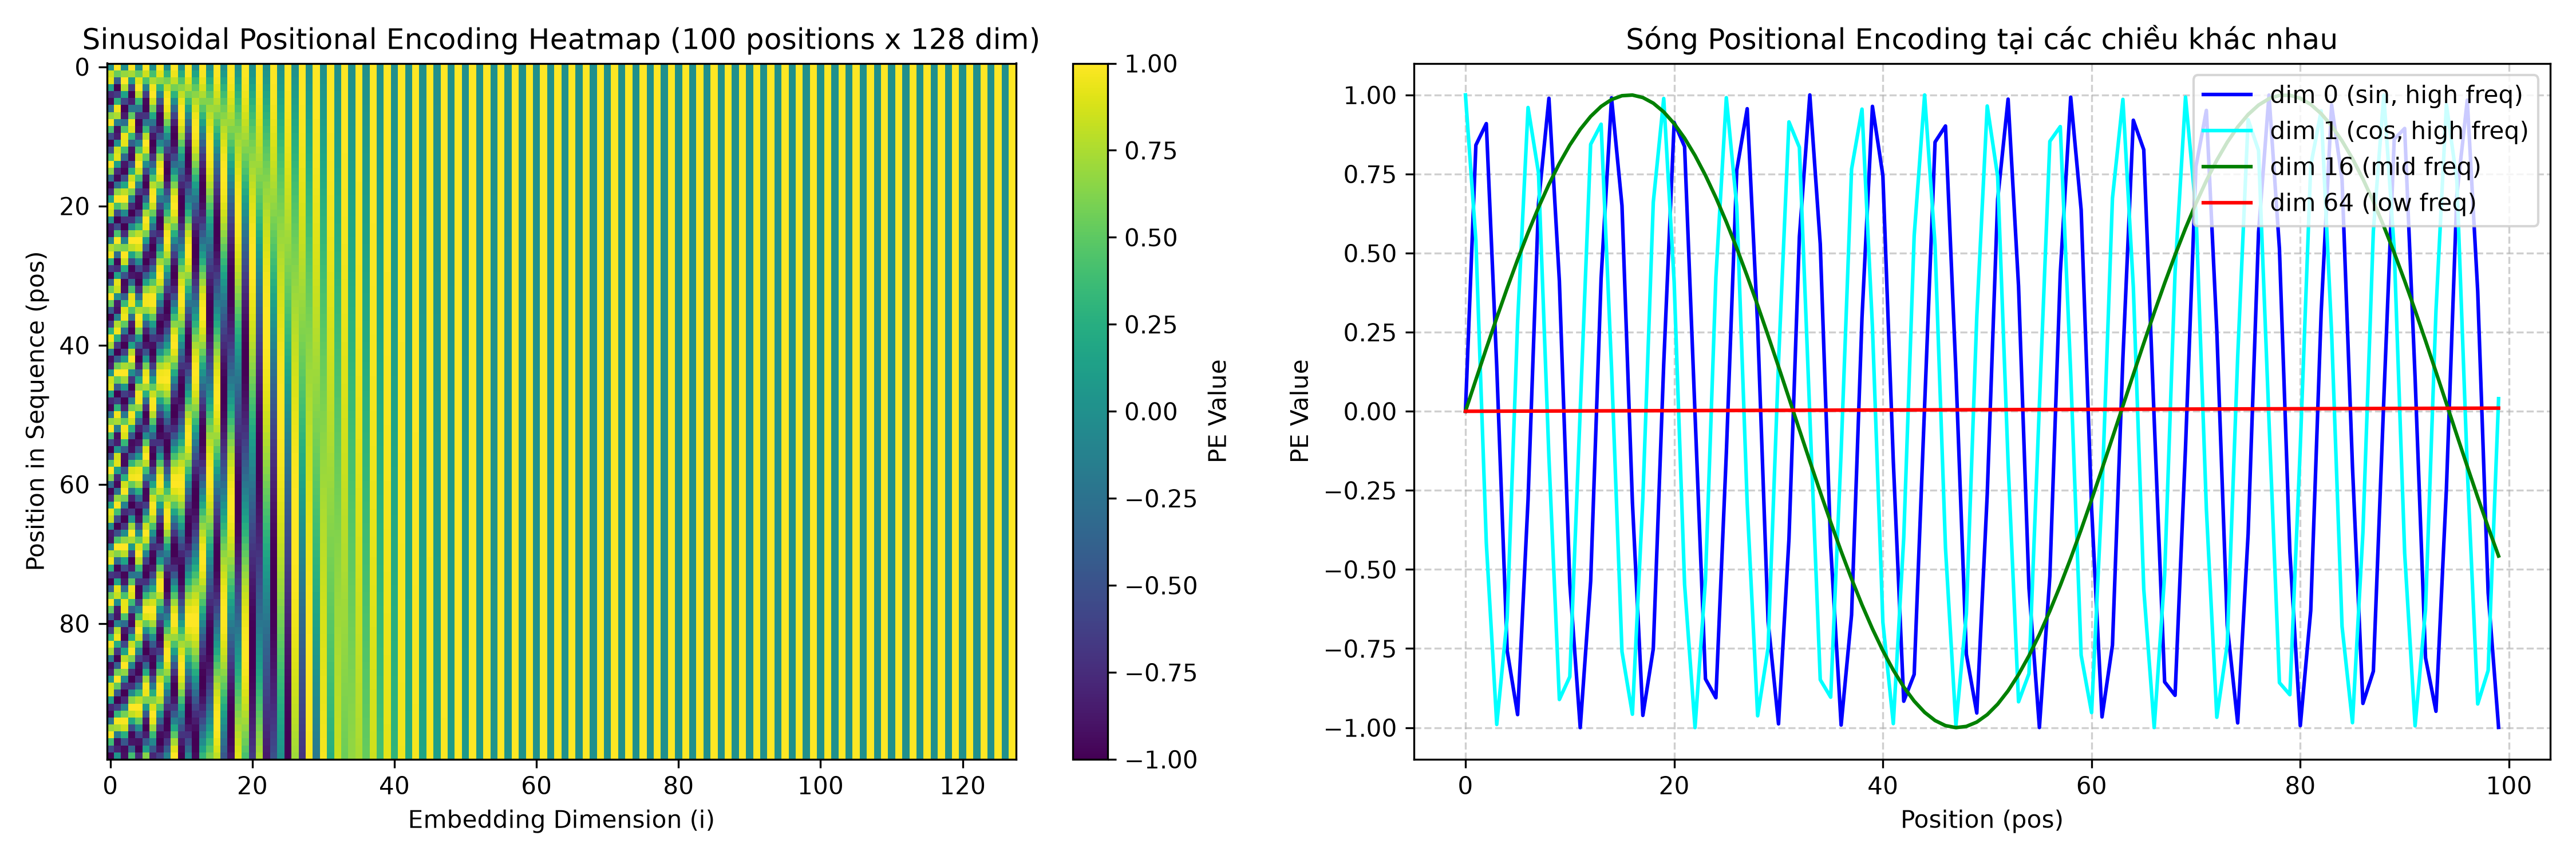

In [4]:
from positional_encoding import PositionalEncoding, get_sinusoidal_encoding_table

# 3.1 Vẽ Heatmap và Sóng Positional Encoding
pe_table = get_sinusoidal_encoding_table(n_position=100, d_model=128)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
im = axes[0].imshow(pe_table, cmap='viridis', aspect='auto')
axes[0].set_title('Sinusoidal Positional Encoding Heatmap (100 pos x 128 dim)', fontsize=12)
axes[0].set_xlabel('Embedding Dimension (i)')
axes[0].set_ylabel('Position in Sequence (pos)')
fig.colorbar(im, ax=axes[0], label='PE Value')

positions = np.arange(100)
axes[1].plot(positions, pe_table[:, 0], label='dim 0 (sin, high freq)', color='blue')
axes[1].plot(positions, pe_table[:, 1], label='dim 1 (cos, high freq)', color='cyan')
axes[1].plot(positions, pe_table[:, 16], label='dim 16 (mid freq)', color='green')
axes[1].plot(positions, pe_table[:, 64], label='dim 64 (low freq)', color='red')
axes[1].set_title('Sóng Positional Encoding tại các chiều khác nhau', fontsize=12)
axes[1].set_xlabel('Position (pos)')
axes[1].set_ylabel('PE Value')
axes[1].legend(loc='upper right')
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('positional_encoding.png', dpi=300)
plt.show()

### Thực nghiệm Hoán vị (Permutation Experiment): `dog bites man` vs `man bites dog`
Mục tiêu: Chứng minh thực nghiệm rằng nếu không có Positional Encoding, Self-Attention không thể phân biệt được hai câu có cùng tập từ ngữ nhưng khác thứ tự.

In [5]:
from transformer_block import TransformerBlock

vocab_small = {'<PAD>': 0, 'dog': 1, 'bites': 2, 'man': 3}
d_model = 128
emb = nn.Embedding(len(vocab_small), d_model)
pe_layer = PositionalEncoding(d_model=d_model, max_len=10, dropout=0.0)
block_no_pe = TransformerBlock(d_model=d_model, n_heads=4, d_ff=256, dropout=0.0)
block_with_pe = TransformerBlock(d_model=d_model, n_heads=4, d_ff=256, dropout=0.0)
block_with_pe.load_state_dict(block_no_pe.state_dict())

s1_ids = torch.tensor([[vocab_small['dog'], vocab_small['bites'], vocab_small['man']]])
s2_ids = torch.tensor([[vocab_small['man'], vocab_small['bites'], vocab_small['dog']]])

emb_s1 = emb(s1_ids)
emb_s2 = emb(s2_ids)

# A. Không có Positional Encoding
pool_no_pe_s1 = block_no_pe(emb_s1).mean(dim=1)
pool_no_pe_s2 = block_no_pe(emb_s2).mean(dim=1)
cos_no_pe = F.cosine_similarity(pool_no_pe_s1, pool_no_pe_s2).item()
diff_no_pe = torch.norm(pool_no_pe_s1 - pool_no_pe_s2).item()

# B. Có Positional Encoding
pool_pe_s1 = block_with_pe(pe_layer(emb_s1)).mean(dim=1)
pool_pe_s2 = block_with_pe(pe_layer(emb_s2)).mean(dim=1)
cos_pe = F.cosine_similarity(pool_pe_s1, pool_pe_s2).item()
diff_pe = torch.norm(pool_pe_s1 - pool_pe_s2).item()

print('Kết quả Permutation Experiment:')
print(f'  - KHÔNG có PE: Cosine Similarity = {cos_no_pe:.6f} | L2 Difference = {diff_no_pe:.6f}')
print(f'  - CÓ PE:       Cosine Similarity = {cos_pe:.6f} | L2 Difference = {diff_pe:.6f}')

Kết quả Permutation Experiment:
  - KHÔNG có PE: Cosine Similarity = 1.000000 | L2 Difference = 0.000001
  - CÓ PE:       Cosine Similarity = 0.999212 | L2 Difference = 0.384638


## 4. Xây dựng Khối Transformer Encoder và Kiểm tra Shape (Mục 18)
Khối `TransformerBlock` tự ghép từ các primitive layers theo đúng sơ đồ:
$$X \to \text{MultiHead Self-Attention} \to \text{Add \& Norm} \to \text{FFN} \to \text{Add \& Norm} \to \text{Output}$$
Tuyệt đối không dùng `nn.TransformerEncoderLayer`.

In [6]:
# Kiểm tra shape tensor chi tiết theo Mục 18 đề bài
B, T, d_model, n_heads, d_ff = 8, 100, 128, 4, 512
d_k = d_model // n_heads  # 128 / 4 = 32

block = TransformerBlock(d_model=d_model, n_heads=n_heads, d_ff=d_ff, dropout=0.1)
dummy_x = torch.randn(B, T, d_model)
out, attn = block(dummy_x, return_attention=True)

print(f'Input X shape:          {dummy_x.shape}')
print(f'Attention Scores shape: {attn.shape} (Kỳ vọng: (8, 4, 100, 100))')
print(f'Output shape:           {out.shape} (Kỳ vọng: (8, 100, 128))')
assert tuple(attn.shape) == (8, 4, 100, 100)
assert tuple(out.shape) == (8, 100, 128)
print('-> Shape check PASSED!')

Input X shape:          torch.Size([8, 100, 128])
Attention Scores shape: torch.Size([8, 4, 100, 100]) (Kỳ vọng: (8, 4, 100, 100))
Output shape:           torch.Size([8, 100, 128]) (Kỳ vọng: (8, 100, 128))
-> Shape check PASSED!


## 5. Định nghĩa Mô hình Phân loại Văn bản (Classifier Models)
Xây dựng hai mô hình để so sánh:
1. `TransformerClassifier`: Gồm Embedding $\to$ PE $\to$ TransformerBlock $\to$ Pooling $\to$ Linear Classifier.
2. `LSTMClassifier`: Gồm Embedding $\to$ LSTM $\to$ Last Hidden State $\to$ Linear Classifier (baseline từ LAB 05).

In [7]:
class TransformerClassifier(nn.Module):
    def __init__(self, vocab_size, d_model=128, n_heads=4, d_ff=256, max_len=500, dropout=0.1, pooling='mean'):
        super().__init__()
        self.d_model = d_model
        self.pooling = pooling
        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=0)
        self.scale = math.sqrt(d_model)
        self.pe = PositionalEncoding(d_model=d_model, max_len=max_len, dropout=dropout)
        self.block = TransformerBlock(d_model=d_model, n_heads=n_heads, d_ff=d_ff, dropout=dropout)
        self.classifier = nn.Linear(d_model, 1)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, return_attention=False):
        mask = (x != 0).unsqueeze(1).unsqueeze(2)  # (B, 1, 1, T)
        emb = self.embedding(x) * self.scale
        emb = self.pe(emb)

        if return_attention:
            out, attn_weights = self.block(emb, mask=mask, return_attention=True)
        else:
            out = self.block(emb, mask=mask, return_attention=False)
            attn_weights = None

        if self.pooling == 'mean':
            pad_mask = (x != 0).unsqueeze(-1).float()
            sum_embeddings = (out * pad_mask).sum(dim=1)
            sum_mask = pad_mask.sum(dim=1).clamp(min=1e-9)
            pooled = sum_embeddings / sum_mask
        elif self.pooling == 'cls':
            pooled = out[:, 0, :]
        else:
            pooled = out.mean(dim=1)

        logits = self.classifier(self.dropout(pooled)).squeeze(-1)
        if return_attention:
            return logits, attn_weights
        return logits

class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, hidden_dim=64, dropout=0.1):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        emb = self.dropout(self.embedding(x))
        out, (h_n, c_n) = self.lstm(emb)
        last_hidden = h_n[-1]
        return self.fc(self.dropout(last_hidden)).squeeze(-1)

def train_and_eval(model, train_loader, val_loader, test_loader, epochs=3, lr=0.001):
    torch.manual_seed(SEED)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.BCEWithLogitsLoss()
    train_losses, val_losses = [], []
    start_time = time.perf_counter()
    for ep in range(epochs):
        model.train()
        total_train_loss = 0.0
        for bx, by in train_loader:
            optimizer.zero_grad()
            loss = criterion(model(bx), by)
            loss.backward()
            optimizer.step()
            total_train_loss += loss.item() * len(by)
        train_loss = total_train_loss / len(train_loader.dataset)
        train_losses.append(train_loss)

        model.eval()
        total_val_loss = 0.0
        with torch.no_grad():
            for bx, by in val_loader:
                total_val_loss += criterion(model(bx), by).item() * len(by)
        val_loss = total_val_loss / len(val_loader.dataset)
        val_losses.append(val_loss)
    total_time = time.perf_counter() - start_time

    model.eval()
    all_probs, all_preds = [], []
    with torch.no_grad():
        for bx, _ in test_loader:
            probs = torch.sigmoid(model(bx)).numpy()
            all_probs.extend(probs)
            all_preds.extend((probs >= 0.5).astype(int))
    all_probs, all_preds = np.array(all_probs), np.array(all_preds)
    y_true = np.array([by.item() for _, by_batch in test_loader for by in by_batch], dtype=int)
    acc = accuracy_score(y_true, all_preds)
    prec = precision_score(y_true, all_preds, zero_division=0)
    rec = recall_score(y_true, all_preds, zero_division=0)
    f1 = f1_score(y_true, all_preds, zero_division=0)
    params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return {'params': params, 'time': total_time, 'acc': acc, 'prec': prec, 'rec': rec, 'f1': f1,
            'train_losses': train_losses, 'val_losses': val_losses, 'probs': all_probs, 'preds': all_preds, 'y_true': y_true}

## 6. Experiment 2 — Number of Attention Heads
Khảo sát khi cố định $d_{model} = 128$, thay đổi số lượng Attention Heads $n_{heads} \in \{1, 2, 4, 8\}$, dẫn đến $d_k = d_{model} / n_{heads} \in \{128, 64, 32, 16\}$.

In [8]:
exp2_results = []
models_by_head = {}
for h in [1, 2, 4, 8]:
    d_k = 128 // h
    model = TransformerClassifier(vocab_size=VOCAB_SIZE, d_model=128, n_heads=h, d_ff=256, dropout=0.1, pooling='mean')
    m = train_and_eval(model, train_loader_100, val_loader_100, test_loader_100, epochs=3, lr=0.001)
    models_by_head[h] = (model, m)
    exp2_results.append({
        'Heads': h, 'd_k': d_k, 'Parameters': m['params'],
        'Training time': round(m['time'], 2), 'Accuracy': round(m['acc'], 4), 'F1': round(m['f1'], 4)
    })

df_exp2 = pd.DataFrame(exp2_results)
display(df_exp2)

Heads,d_k,Parameters,Training time,Accuracy,F1
1,128,1412609,87.57,0.6972,0.6919
2,64,1412609,112.03,0.7324,0.7402
4,32,1412609,123.27,0.7312,0.7417
8,16,1412609,148.25,0.7428,0.7532


## 7. Experiment 3 — Attention Head Diversity
Trích xuất và trực quan hóa ma trận Attention Weights $(4 \times T \times T)$ của mô hình 4 heads trên câu ví dụ:
*"this movie was truly fantastic with brilliant acting and great directing"*

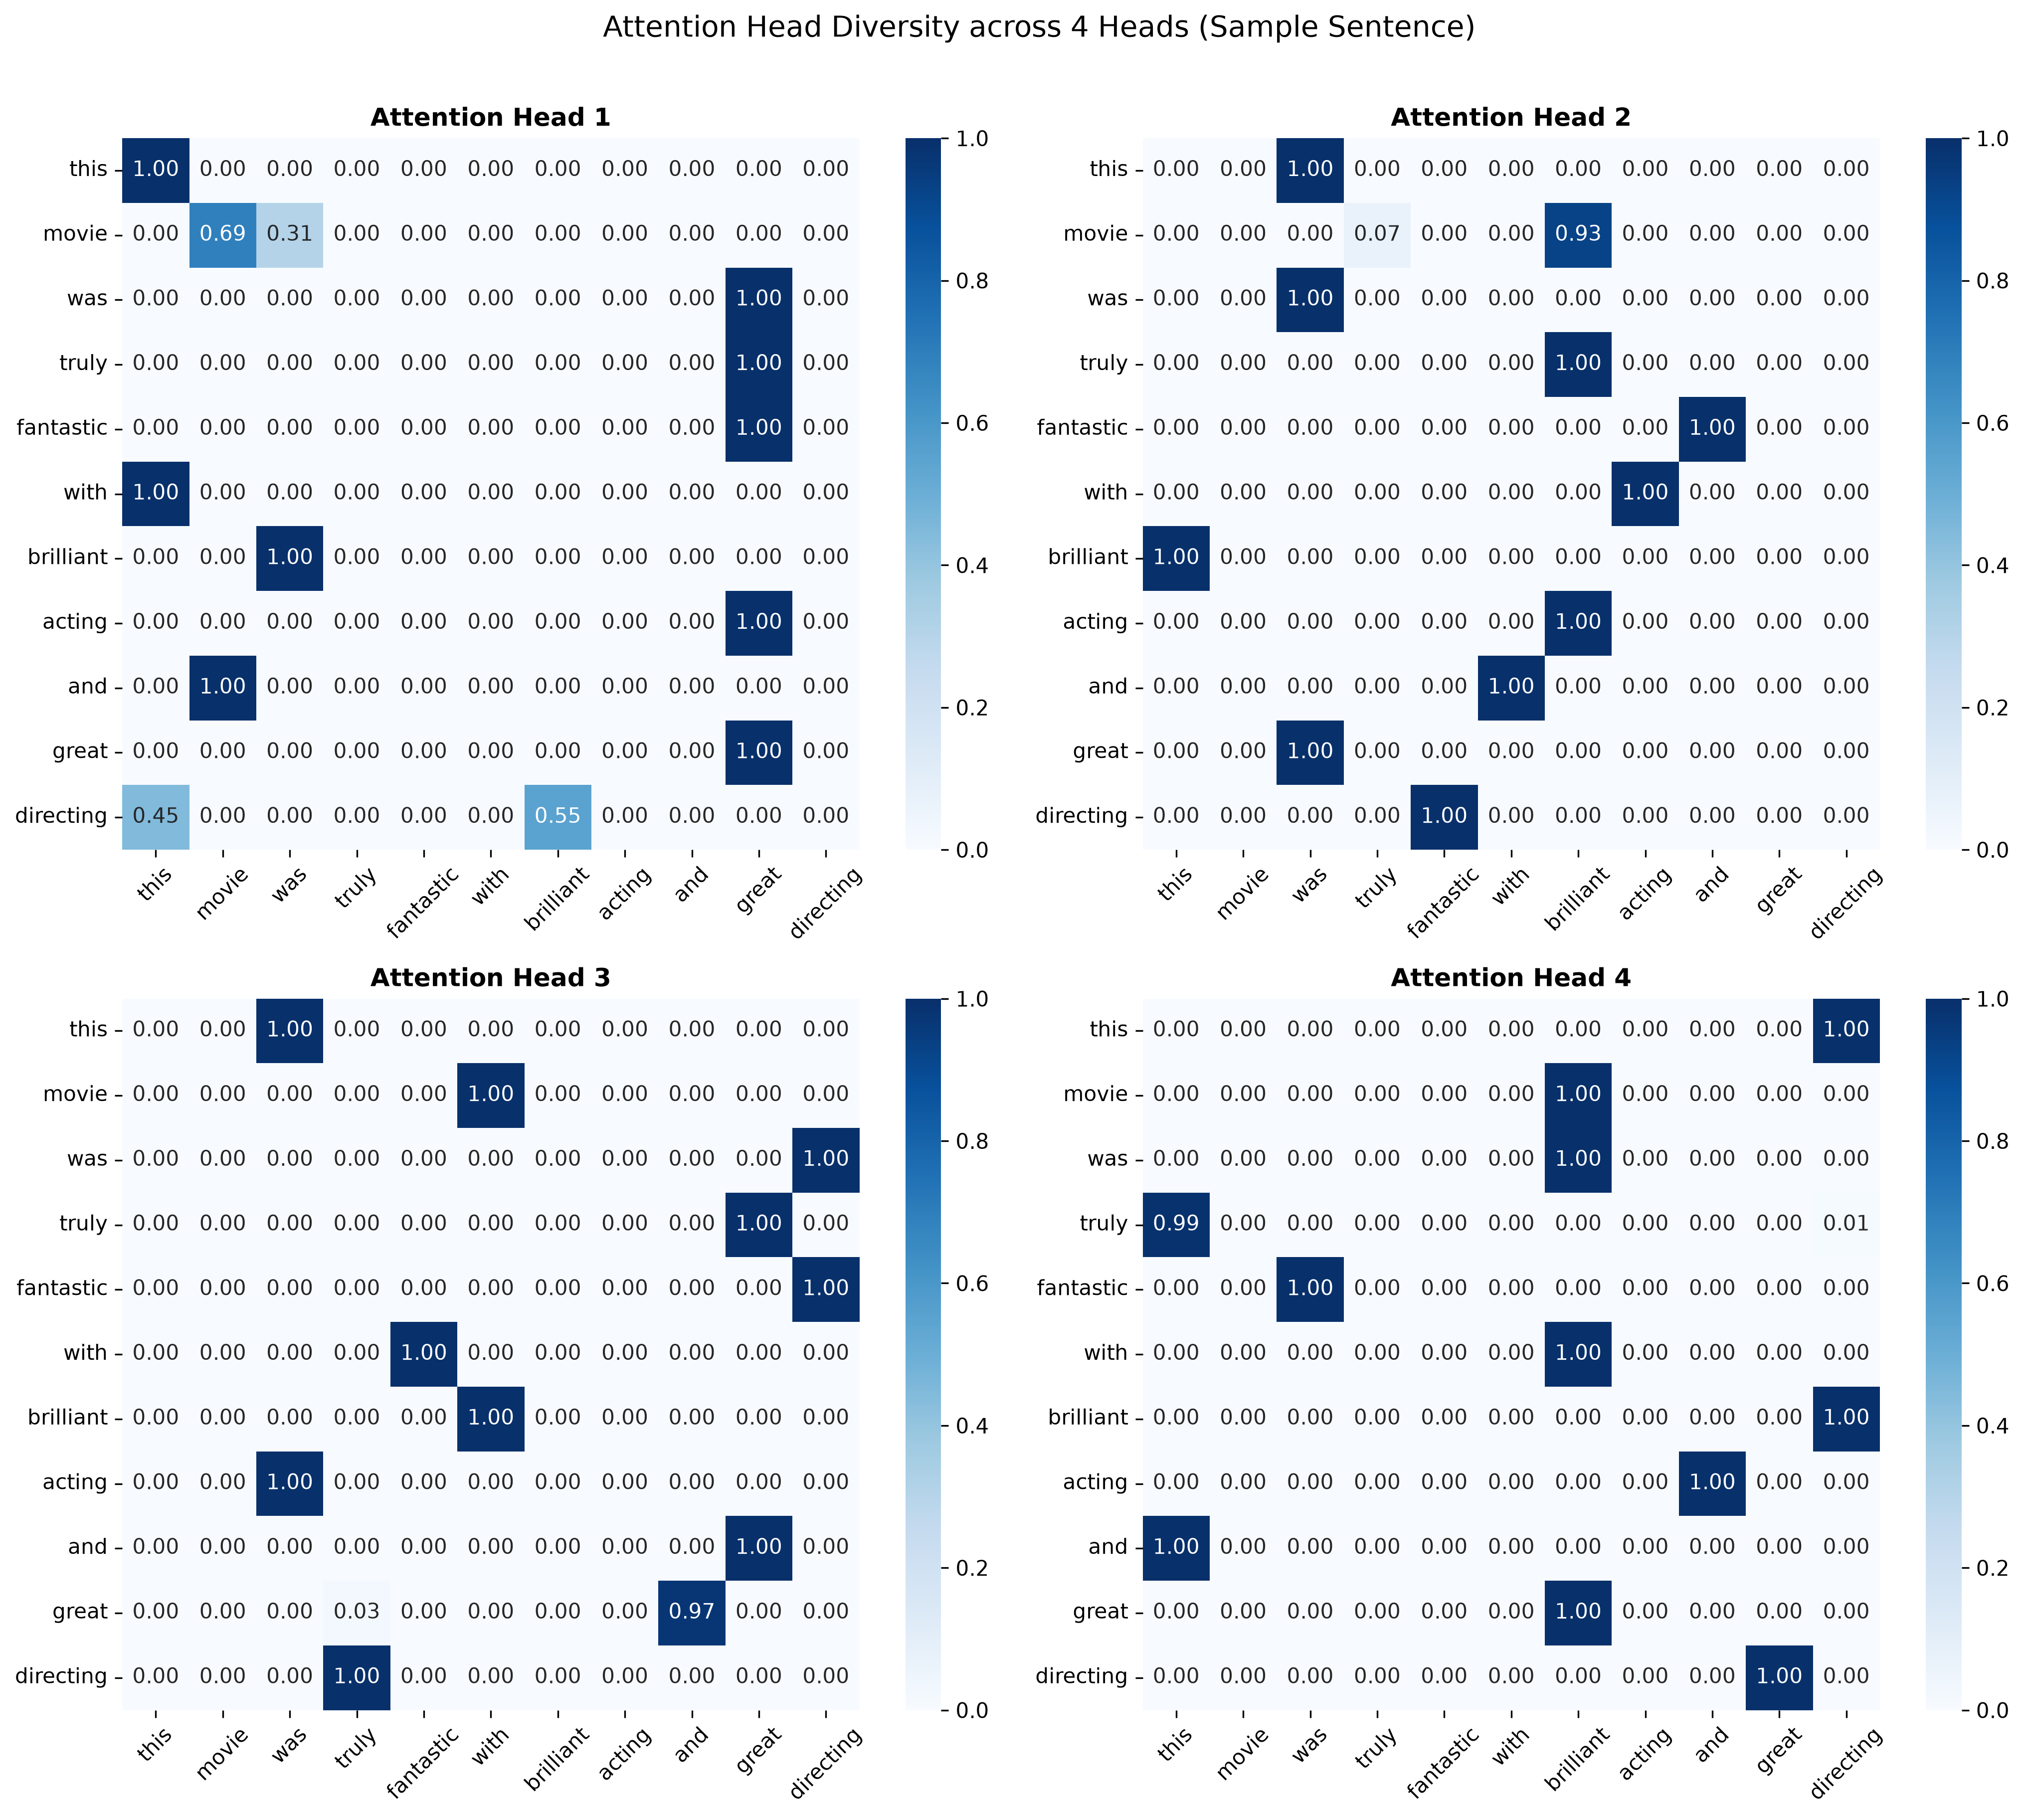

In [9]:
best_model_4h, best_metrics_4h = models_by_head[4]
sample_text = 'this movie was truly fantastic with brilliant acting and great directing'
sample_tokens = tokenize(sample_text)
sample_ids = torch.tensor([[vocab.get(w, 1) for w in sample_tokens]], dtype=torch.long)

best_model_4h.eval()
with torch.no_grad():
    _, attn_weights = best_model_4h(sample_ids, return_attention=True)
    attn_weights = attn_weights.squeeze(0).numpy()

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()
n_words = len(sample_tokens)
for h_idx in range(4):
    ax = axes[h_idx]
    mat = attn_weights[h_idx, :n_words, :n_words]
    sns.heatmap(mat, ax=ax, cmap='Blues', annot=True, fmt='.2f',
                xticklabels=sample_tokens, yticklabels=sample_tokens, cbar=True)
    ax.set_title(f'Attention Head {h_idx + 1}', fontsize=12, fontweight='bold')
    ax.tick_params(axis='x', rotation=45)

plt.suptitle('Attention Head Diversity across 4 Heads', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('attention_heads.png', dpi=300, bbox_inches='tight')
plt.show()

## 8. Experiment 4 — Transformer vs RNN/LSTM Comparison
So sánh hiệu năng giữa mô hình tuần tự (LSTM từ LAB 05) và mô hình chú ý trực tiếp (Transformer Encoder) trên cùng tập dữ liệu và siêu tham số.

In [10]:
lstm_model = LSTMClassifier(vocab_size=VOCAB_SIZE, embed_dim=128, hidden_dim=64, dropout=0.1)
lstm_metrics = train_and_eval(lstm_model, train_loader_100, val_loader_100, test_loader_100, epochs=3, lr=0.001)
transformer_metrics = best_metrics_4h

exp4_results = [
    {'Model': 'LSTM', 'Parameters': lstm_metrics['params'], 'Training time': round(lstm_metrics['time'], 2),
     'Accuracy': round(lstm_metrics['acc'], 4), 'Precision': round(lstm_metrics['prec'], 4),
     'Recall': round(lstm_metrics['rec'], 4), 'F1': round(lstm_metrics['f1'], 4)},
    {'Model': 'Transformer', 'Parameters': transformer_metrics['params'], 'Training time': round(transformer_metrics['time'], 2),
     'Accuracy': round(transformer_metrics['acc'], 4), 'Precision': round(transformer_metrics['prec'], 4),
     'Recall': round(transformer_metrics['rec'], 4), 'F1': round(transformer_metrics['f1'], 4)}
]
df_exp4 = pd.DataFrame(exp4_results)
display(df_exp4)

Model,Parameters,Training time,Accuracy,Precision,Recall,F1
LSTM,1329729,20.92,0.6400,0.6160,0.7970,0.6949
Transformer,1412609,123.27,0.7312,0.7333,0.7504,0.7417


## 9. Experiment 5 — Sequence Length & Complexity $O(T^2)$
Khảo sát khi tăng độ dài chuỗi $T \in \{32, 64, 128, 256\}$, số lượng phần tử của Attention Matrix tăng theo hàm bậc hai $T^2$ ($1024 \to 4096 \to 16384 \to 65536$).

In [11]:
exp5_results = []
for L in [32, 64, 128, 256]:
    retained_pct = 100.0 * np.mean([min(len(words), L) / max(len(words), 1) for words in sub_train_tokens])
    attn_mem = L * L
    tl = make_loader(sub_train_df, sub_train_tokens, max_len=L, batch_size=128, shuffle=True)
    vl = make_loader(sub_val_df, sub_val_tokens, max_len=L, batch_size=128, shuffle=False)
    tel = make_loader(sub_test_df, sub_test_tokens, max_len=L, batch_size=128, shuffle=False)
    model_L = TransformerClassifier(vocab_size=VOCAB_SIZE, d_model=128, n_heads=4, d_ff=256, max_len=300, dropout=0.1, pooling='mean')
    m_L = train_and_eval(model_L, tl, vl, tel, epochs=2, lr=0.001)
    exp5_results.append({
        'Length': L, 'Tokens retained': f'{retained_pct:.2f}%', 'Attention memory': attn_mem,
        'Training time': round(m_L['time'], 2), 'F1': round(m_L['f1'], 4)
    })

df_exp5 = pd.DataFrame(exp5_results)
display(df_exp5)

Length,Tokens retained,Attention memory,Training time,F1
32,20.58%,1024,18.91,0.6232
64,39.58%,4096,41.42,0.6941
128,69.04%,16384,124.34,0.7450
256,89.95%,65536,257.88,0.7699


## 10. Experiment 6 — Pooling Strategy
So sánh chiến lược trích xuất vector biểu diễn toàn câu: **Mean Pooling** (trung bình các token) vs **CLS-style Pooling** (lấy vector token đầu tiên).

In [12]:
cls_model = TransformerClassifier(vocab_size=VOCAB_SIZE, d_model=128, n_heads=4, d_ff=256, dropout=0.1, pooling='cls')
cls_metrics = train_and_eval(cls_model, train_loader_100, val_loader_100, test_loader_100, epochs=3, lr=0.001)

exp6_results = [
    {'Pooling': 'Mean', 'Accuracy': round(best_metrics_4h['acc'], 4), 'F1': round(best_metrics_4h['f1'], 4), 'Training time': round(best_metrics_4h['time'], 2)},
    {'Pooling': 'CLS-style', 'Accuracy': round(cls_metrics['acc'], 4), 'F1': round(cls_metrics['f1'], 4), 'Training time': round(cls_metrics['time'], 2)}
]
df_exp6 = pd.DataFrame(exp6_results)
display(df_exp6)

Pooling,Accuracy,F1,Training time
Mean,0.7312,0.7417,123.27
CLS-style,0.5732,0.6041,98.73


## 11. Đồ thị Quá trình Huấn luyện (Learning Curves) và Ma trận Nhầm lẫn (Confusion Matrix)
Xuất các file kết quả `learning_curves.png` và `confusion_matrix.png` theo quy định deliverables.

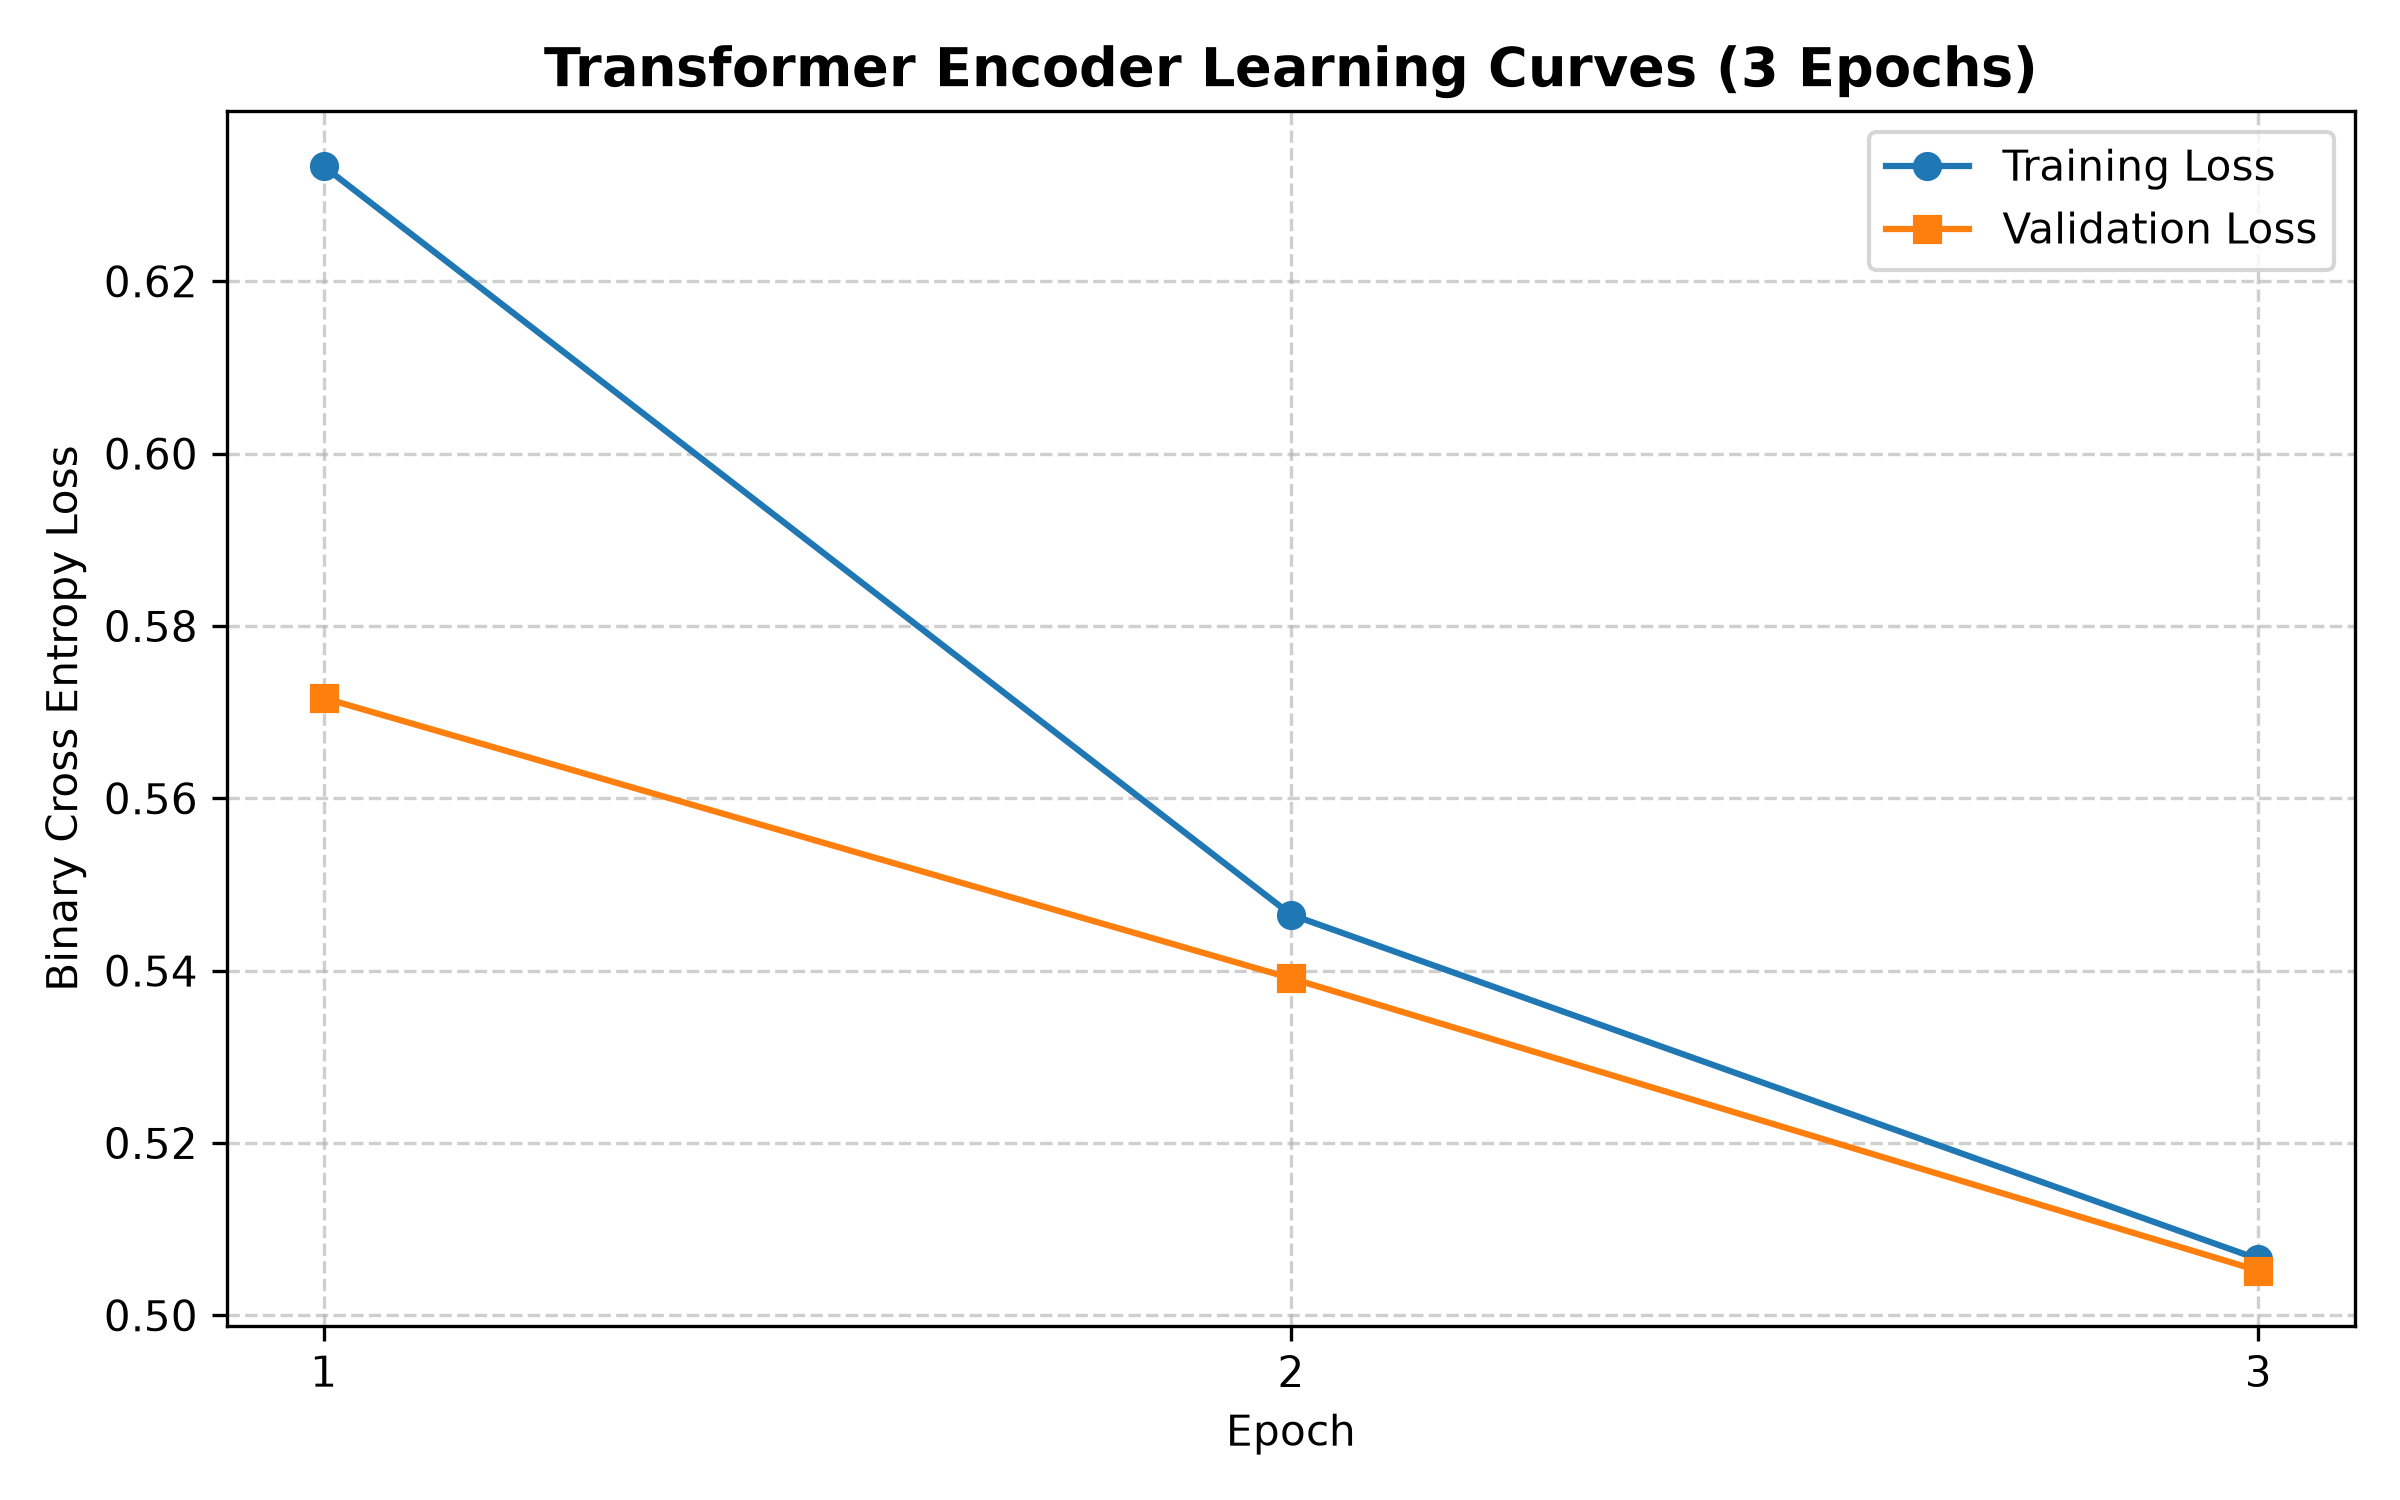

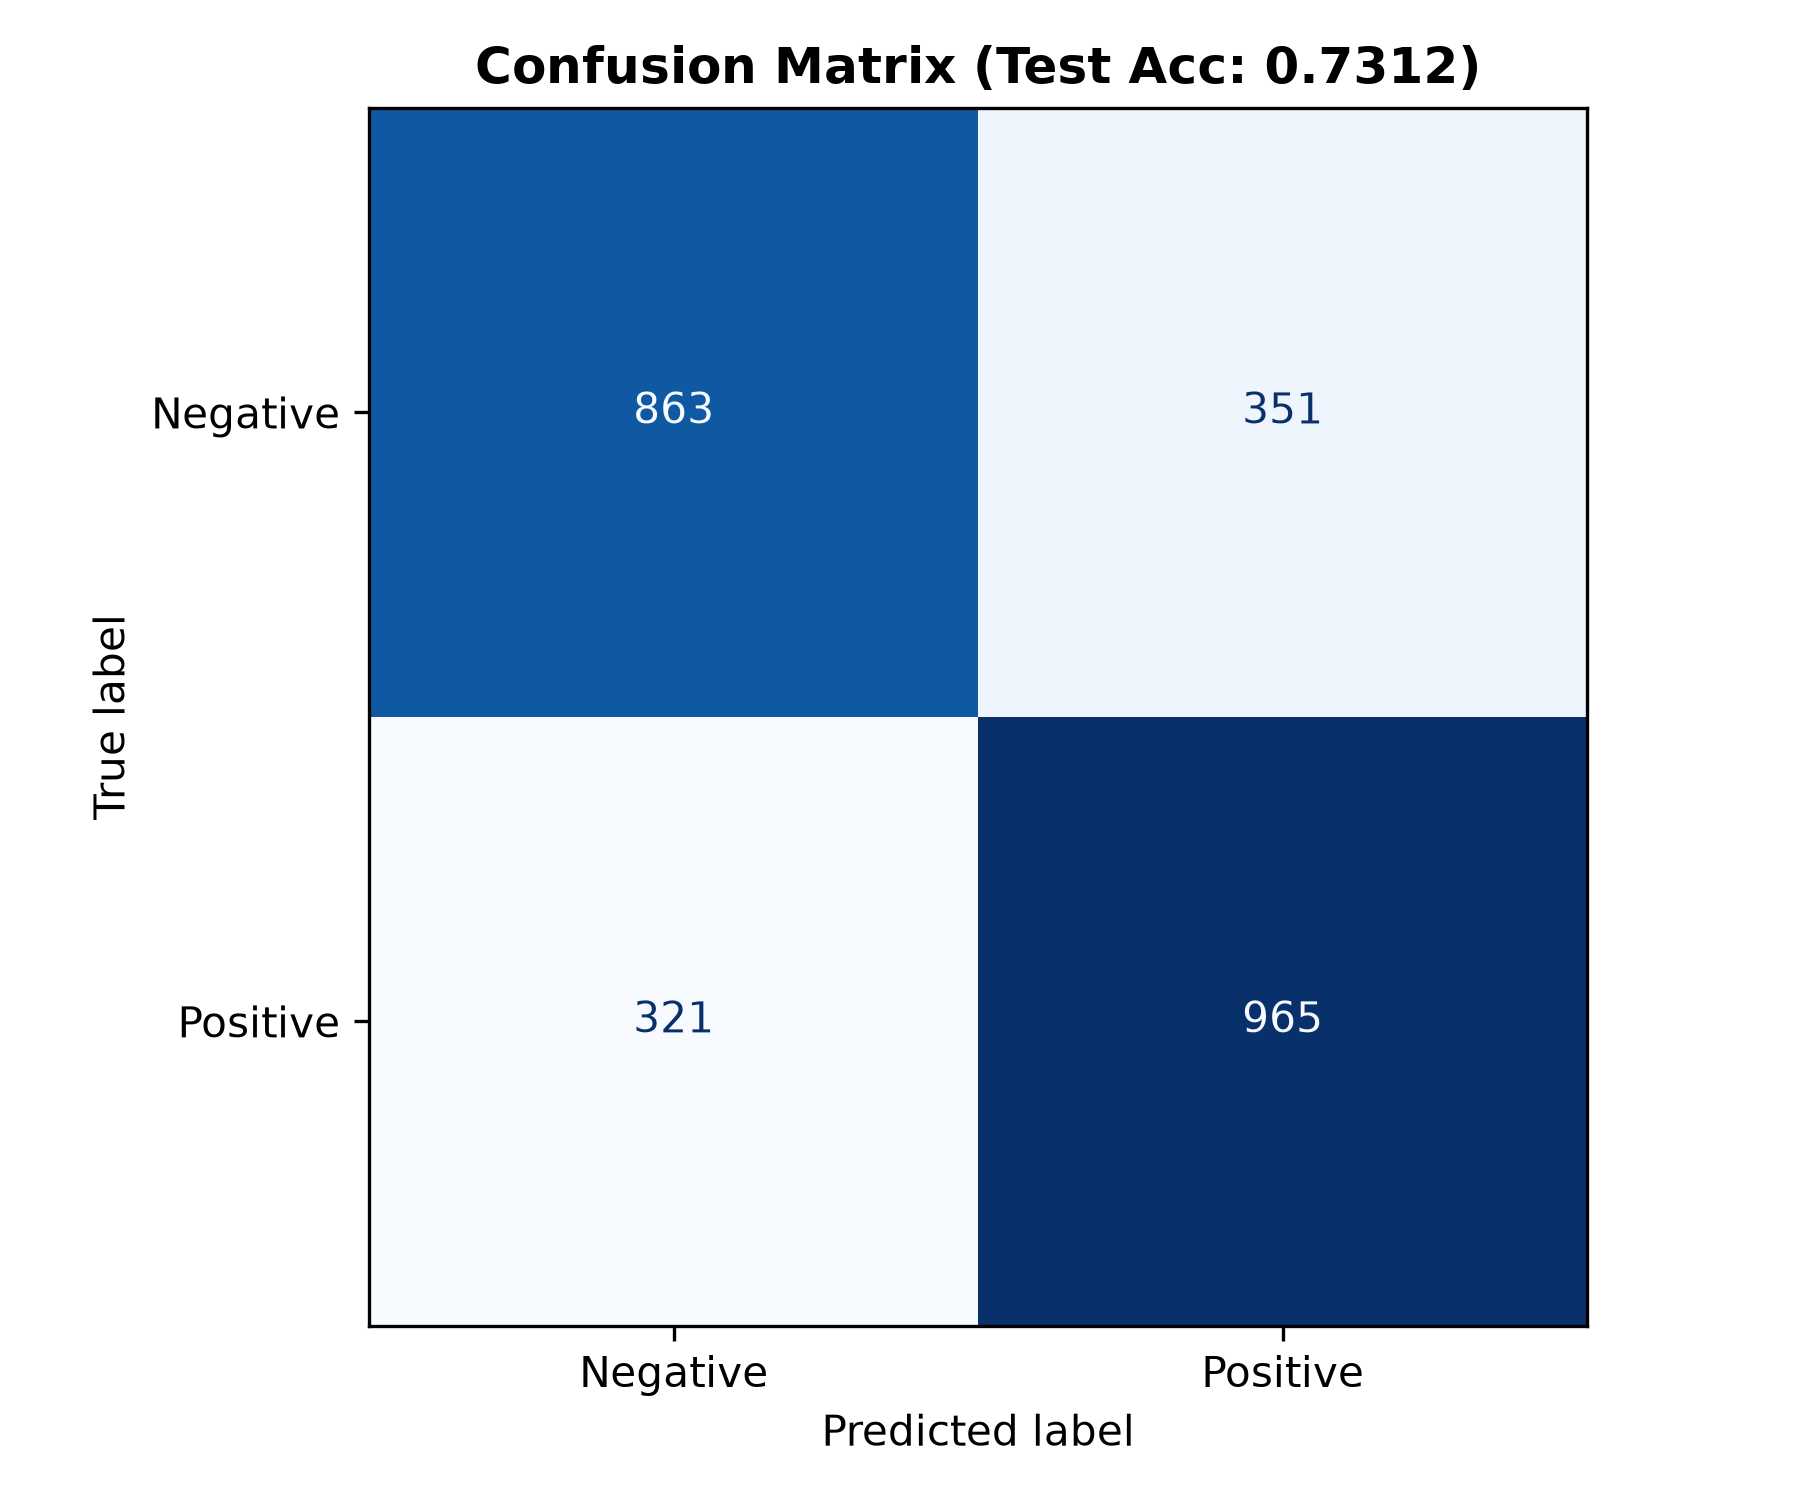

In [13]:
# Learning Curves
fig, ax = plt.subplots(figsize=(8, 5))
ep_range = range(1, len(transformer_metrics['train_losses']) + 1)
ax.plot(ep_range, transformer_metrics['train_losses'], marker='o', label='Training Loss', color='#1f77b4')
ax.plot(ep_range, transformer_metrics['val_losses'], marker='s', label='Validation Loss', color='#ff7f0e')
ax.set_title('Transformer Encoder Learning Curves (3 Epochs)', fontsize=13, fontweight='bold')
ax.set_xlabel('Epoch')
ax.set_ylabel('Binary Cross Entropy Loss')
ax.set_xticks(ep_range)
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend()
plt.tight_layout()
plt.savefig('learning_curves.png', dpi=300)
plt.show()

# Confusion Matrix
cm = confusion_matrix(transformer_metrics['y_true'], transformer_metrics['preds'])
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Negative', 'Positive'])
disp.plot(cmap='Blues', ax=ax, colorbar=False)
ax.set_title(f'Confusion Matrix (Test Acc: {transformer_metrics["acc"]:.4f})', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=300)
plt.show()

## 12. Đánh giá Định tính các Trường hợp Đặc biệt (Mục 23)
Kiểm tra mô hình trên các câu có cấu trúc đặc biệt: câu ngắn, câu dài, phủ định, câu tương phản, câu có cảm xúc mơ hồ.

In [14]:
test_sentences = [
    ('Short', 'I really enjoyed this movie.'),
    ('Long', 'While the initial premise of the film promised an insightful exploration of human nature, the convoluted screenplay and amateurish cinematography completely derailed the experience.'),
    ('Negation', 'This movie was not good at all, completely disappointing.'),
    ('Contrast', 'The cinematography was breathtaking and the actors were great, but the plot was utterly terrible.'),
    ('Ambiguous', 'An interesting experience that leaves viewers questioning what they just watched.')
]

best_model_4h.eval()
print('Kết quả đánh giá định tính:')
for label, s in test_sentences:
    toks = tokenize(s)
    ids = torch.tensor([[vocab.get(w, 1) for w in toks[:100]]], dtype=torch.long)
    with torch.no_grad():
        lg = best_model_4h(ids)
        pr = torch.sigmoid(lg).item()
        pred_sentiment = 'Positive' if pr >= 0.5 else 'Negative'
    print(f'  [{label:9s}] {pred_sentiment:8s} (P(pos)={pr:.4f}) | "{s}"')

Kết quả đánh giá định tính:
  [Short    ] Negative (P(pos)=0.0133) | "I really enjoyed this movie."
  [Long     ] Positive (P(pos)=0.7274) | "While the initial premise of the film promised an insightful exploration of human nature, the convoluted screenplay and amateurish cinematography completely derailed the experience."
  [Negation ] Negative (P(pos)=0.0155) | "This movie was not good at all, completely disappointing."
  [Contrast ] Negative (P(pos)=0.3060) | "The cinematography was breathtaking and the actors were great, but the plot was utterly terrible."
  [Ambiguous] Negative (P(pos)=0.0309) | "An interesting experience that leaves viewers questioning what they just watched."


## 13. Xuất kết quả tổng hợp vào `results.csv`
Lưu các bảng số liệu thực nghiệm vào file `results.csv` theo định dạng chuẩn.

In [15]:
with open('results.csv', 'w', encoding='utf-8') as f:
    f.write('# Experiment 2: Number of attention heads\n')
    df_exp2.to_csv(f, index=False)
    f.write('\n# Experiment 4: Transformer vs LSTM\n')
    df_exp4.to_csv(f, index=False)
    f.write('\n# Experiment 5: Sequence length\n')
    df_exp5.to_csv(f, index=False)
    f.write('\n# Experiment 6: Pooling strategy\n')
    df_exp6.to_csv(f, index=False)
print('-> Đã lưu dữ liệu đầy đủ vào results.csv thành công!')

-> Đã lưu dữ liệu đầy đủ vào results.csv thành công!
